# Week 3 - Noise filtering
Necessary imports

In [1]:
from __future__ import annotations
import cv2
import matplotlib.pyplot as plt
import pickle
from dataclasses import dataclass
from pathlib import Path
import random, math, ast, sys

import pandas as pd
import numpy as np
from skimage.feature import local_binary_pattern
from skimage.filters import threshold_otsu
from skimage.metrics import structural_similarity

In [2]:
def find_project_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "data").is_dir() and (directory / "src").is_dir():
            return directory
    raise FileNotFoundError("Could not find the project root")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"

## 0. Image and ground truth loading
Code snippet from week1 code so it stays with a persistent method

In [3]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [4]:
train_dataset = load_image_dataset(f"{DATA_DIR}/qsd1_w4")
non_augmented_data = load_image_dataset(f"{DATA_DIR}/qsd1_w4/non_augmented")
ground_truth = load_ground_truth(f"{DATA_DIR}/qsd1_w4/gt_corresps.pkl")

In [5]:
train_dataset.ids

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])

## Image analysis

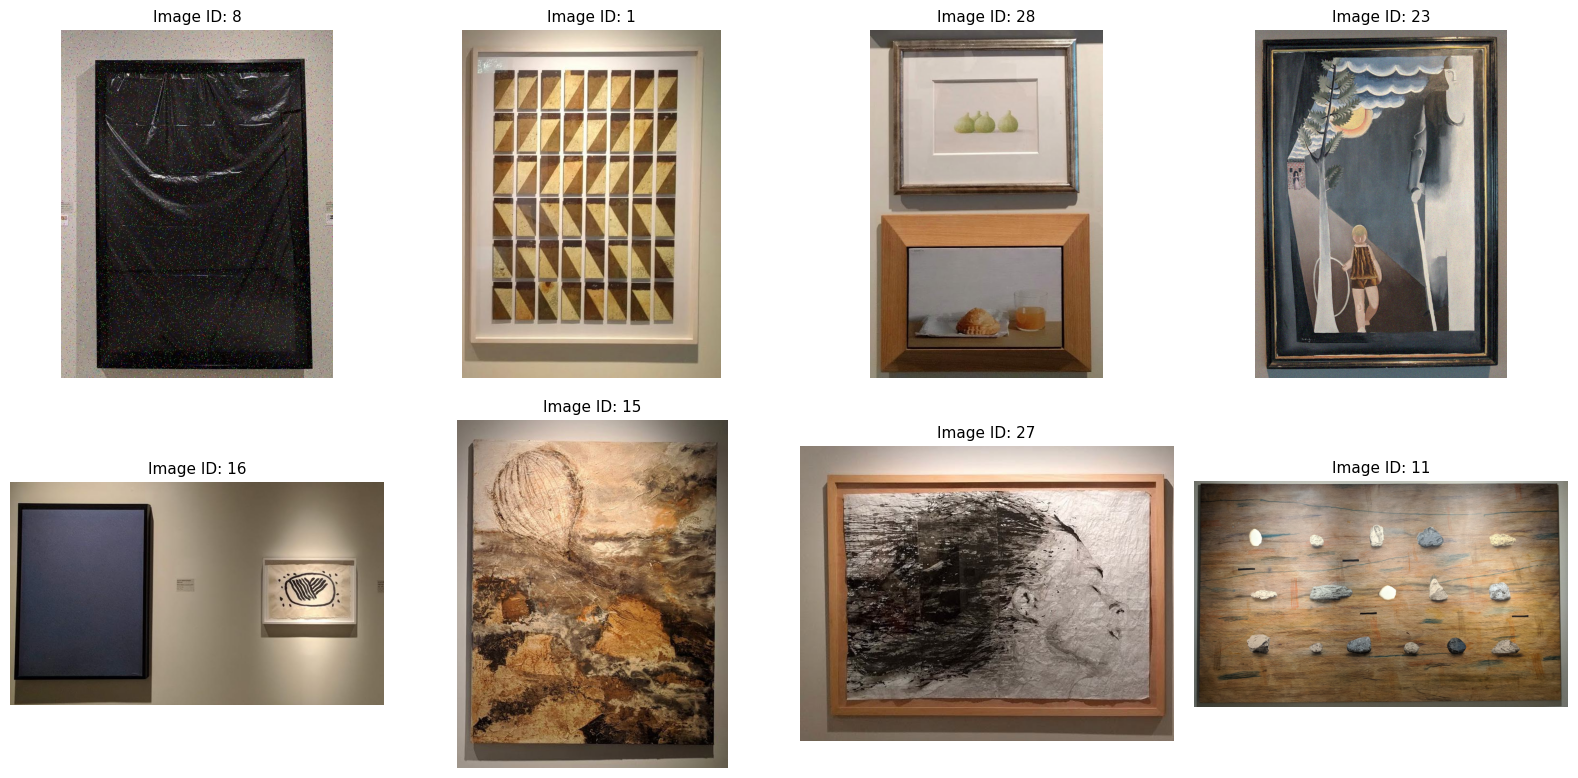

In [6]:
random.seed(52)
n_images = 8

n_cols = 4 
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(n_cols * 4, n_rows * 4)
)

# Make axes iterable even if there's only one row or column
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(n_images):
    random_index = random.randint(0, len(train_dataset.paths) - 1)
    image_path = train_dataset.paths[random_index]
    image_id_value = train_dataset.ids[random_index]

    # Load image and convert BGR to RGB
    image = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image_rgb)
    axes[i].set_title(f"Image ID: {image_id_value}", fontsize=11)
    axes[i].axis("off")

# Hide unused grid cells
for j in range(n_images, len(axes)):
    axes[j].axis("off")

plt.tight_layout(pad=1.5)
plt.show()


In [25]:
import cv2, numpy as np, random
from pathlib import Path

def road_map(gray, m=4):
    g = gray.astype(np.float32)
    p = cv2.copyMakeBorder(g, 1, 1, 1, 1, cv2.BORDER_REFLECT)
    h, w = g.shape
    d = [np.abs(g - p[1+dy:1+dy+h, 1+dx:1+dx+w])
         for dy in (-1, 0, 1) for dx in (-1, 0, 1) if (dy, dx) != (0, 0)]
    return np.sort(np.stack(d), axis=0)[:m].sum(axis=0)

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64))**2)
    return 100.0 if mse == 0 else 10*np.log10(255**2 / mse)   # cap for identical images


def denoise_if_noisy(img_bgr, tp=0.05, tf=0.1):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    if np.mean(road_map(gray) > tp) > tf:
        print(f"Denoising image due to noise level exceeding threshold (tp={tp}, tf={tf})")
        return cv2.medianBlur(img_bgr, 3)
    return img_bgr

Best thresholds: tp=10, tf=0.1 (accuracy=0.733)


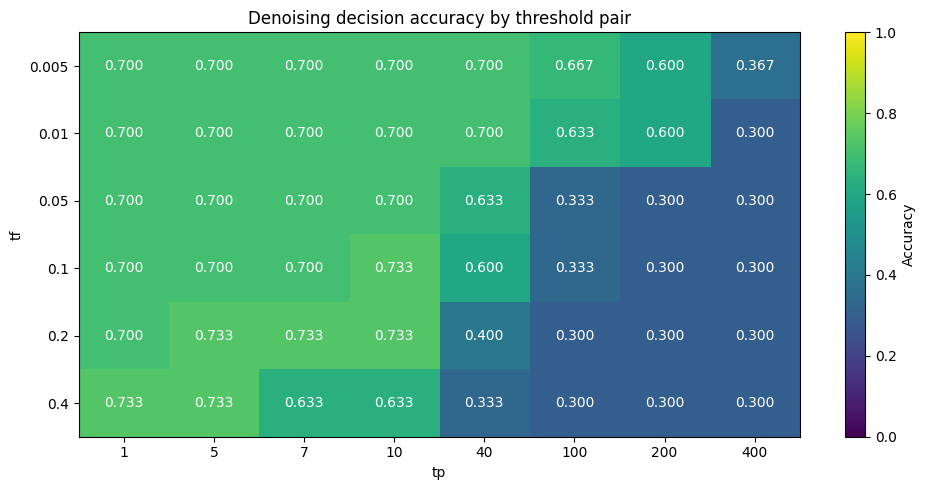

In [38]:
tps = [1,5,7, 10, 40, 100, 200, 400]
tfs = [0.005, 0.01, 0.05, 0.1,0.2, 0.4]

# The non-augmented image is the ground truth for whether denoising is
# needed: an exact pixel match means that the training image is clean.
clean_by_id = dict(zip(non_augmented_data.ids.tolist(), non_augmented_data.paths))
missing_ids = sorted(set(train_dataset.ids.tolist()) - set(clean_by_id))
if missing_ids:
    raise ValueError(f"Missing non-augmented images for IDs: {missing_ids}")

noise_labels = []
road_maps = []
for train_path, image_id_value in zip(train_dataset.paths, train_dataset.ids):
    train_image = cv2.imread(str(train_path), cv2.IMREAD_COLOR)
    clean_image = cv2.imread(str(clean_by_id[int(image_id_value)]), cv2.IMREAD_COLOR)
    if train_image is None or clean_image is None:
        raise ValueError(f"Could not read image pair for ID {image_id_value}")
    if train_image.shape != clean_image.shape:
        raise ValueError(
            f"Shape mismatch for ID {image_id_value}: "
            f"{train_image.shape} vs {clean_image.shape}"
        )
    noise_labels.append(not np.array_equal(train_image, clean_image))
    road_maps.append(road_map(cv2.cvtColor(train_image, cv2.COLOR_BGR2GRAY)))

noise_labels = np.asarray(noise_labels, dtype=bool)
# Keep road maps as a list because images have different shapes.
road_maps = [np.asarray(road_map_value) for road_map_value in road_maps]

accuracy_grid = np.empty((len(tfs), len(tps)), dtype=float)

for tf_index, tf in enumerate(tfs):
    for tp_index, tp in enumerate(tps):
        noise_fraction = np.asarray([
            np.mean(road_map_value > tp)
            for road_map_value in road_maps
        ])

        predicted_noise = noise_fraction > tf
        accuracy_grid[tf_index, tp_index] = np.mean(
            predicted_noise == noise_labels
        )
accuracy_grid = np.empty((len(tfs), len(tps)), dtype=float)

for tf_index, tf in enumerate(tfs):
    for tp_index, tp in enumerate(tps):
        noise_fraction = np.asarray([
            np.mean(road_map_value > tp)
            for road_map_value in road_maps
        ])
        predicted_noise = noise_fraction > tf
        accuracy_grid[tf_index, tp_index] = np.mean(predicted_noise == noise_labels)

best_tf_index, best_tp_index = np.unravel_index(
    np.argmax(accuracy_grid), accuracy_grid.shape
)
best_tf = tfs[best_tf_index]
best_tp = tps[best_tp_index]
best_accuracy = accuracy_grid[best_tf_index, best_tp_index]
print(
    f"Best thresholds: tp={best_tp}, tf={best_tf} "
    f"(accuracy={best_accuracy:.3f})"
)

fig, ax = plt.subplots(figsize=(10, 5))
heatmap = ax.imshow(accuracy_grid, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(tps)), labels=[str(tp) for tp in tps])
ax.set_yticks(range(len(tfs)), labels=[str(tf) for tf in tfs])
ax.set_xlabel("tp")
ax.set_ylabel("tf")
ax.set_title("Denoising decision accuracy by threshold pair")
for tf_index in range(len(tfs)):
    for tp_index in range(len(tps)):
        ax.text(
            tp_index, tf_index, f"{accuracy_grid[tf_index, tp_index]:.3f}",
            ha="center", va="center", color="white"
        )
fig.colorbar(heatmap, ax=ax, label="Accuracy")
fig.tight_layout()
plt.show()


Denoising image due to noise level exceeding threshold (tp=40, tf=0.05)


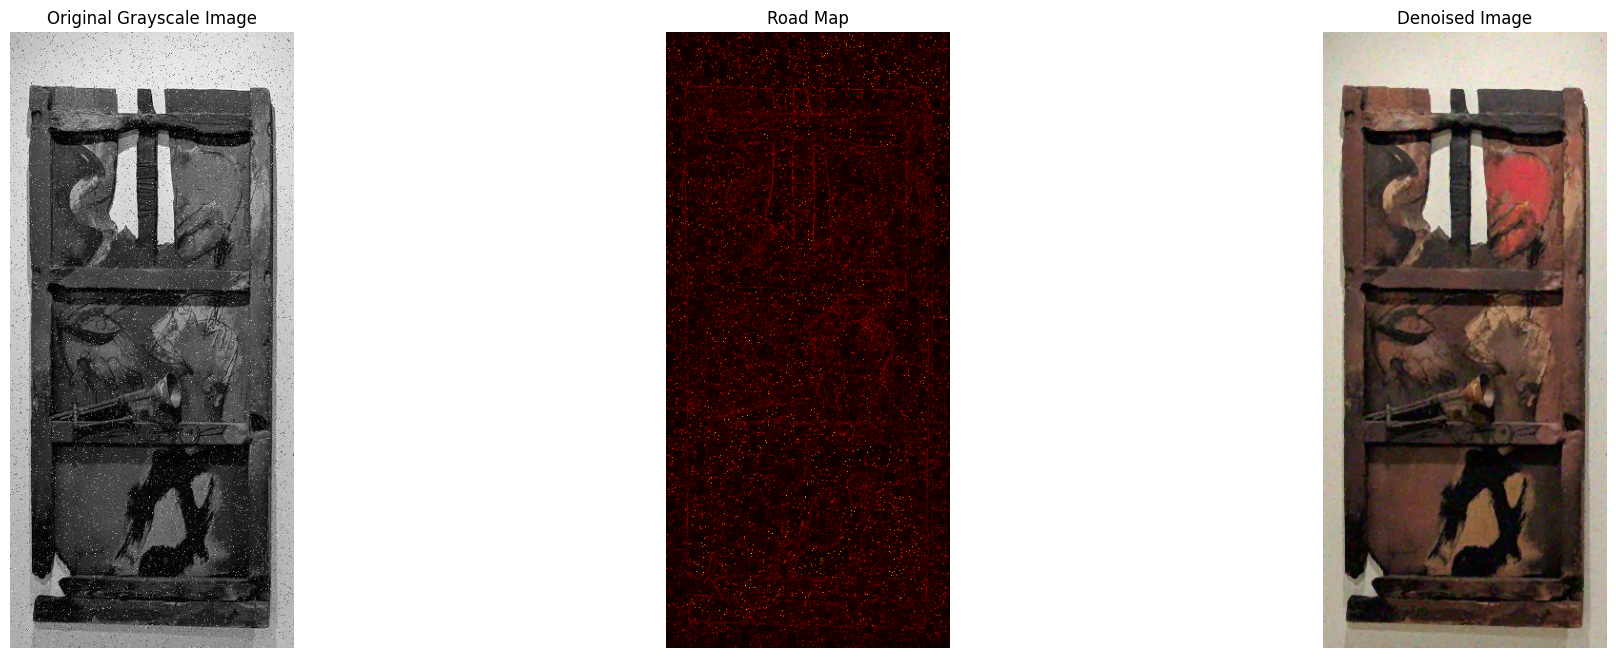

In [45]:
image = cv2.imread(str(train_dataset.paths[22]))

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
roadmap = road_map(gray_image)

denoised_image = denoise_if_noisy(image, tp=40, tf=0.05)

# plot the comparison of the original grayscale image and the roadmap

plt.figure(figsize=(24, 8))
plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(roadmap, cmap="hot")
plt.title("Road Map")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(denoised_image, cv2.COLOR_BGR2RGB))
plt.title("Denoised Image")
plt.axis("off")

# plt.tight_layout()
plt.show()


In [30]:

import cv2
import numpy as np
import pickle
from pathlib import Path
import time

def create_feature_detector(method="SIFT", nfeatures=3000):
    """
    Create one of the three candidate feature extractors.
    """
    method = method.upper()

    if method == "SIFT":
        return cv2.SIFT_create(nfeatures=nfeatures)

    elif method == "ORB":
        return cv2.ORB_create(nfeatures=nfeatures)

    elif method == "AKAZE":
        return cv2.AKAZE_create()

    else:
        raise ValueError(f"Unsupported method: {method}")


def extract_features(dataset, method="SIFT", nfeatures=3000):
    """
    Extract local keypoints and descriptors from every image.

    Returns:
        Dictionary indexed by image ID. Each entry contains:
        - path: original image path
        - keypoints: Nx7 array of keypoint properties
        - descriptors: NxD descriptor matrix, or None
    """
    detector = create_feature_detector(method, nfeatures)

    features = {}
    total_time = 0.0

    for image_path, image_id in zip(dataset.paths, dataset.ids):
        image = cv2.imread(str(image_path))

        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        start = time.perf_counter()
        keypoints, descriptors = detector.detectAndCompute(
            gray, None
        )
        total_time += time.perf_counter() - start

        # Preserve the geometry needed for later matching
        # and potentially geometric verification.
        kp_array = np.array([
            [
                kp.pt[0], kp.pt[1],
                kp.size, kp.angle,
                kp.response, kp.octave,
                kp.class_id
            ]
            for kp in keypoints
        ], dtype=np.float32).reshape(-1, 7)

        features[int(image_id)] = {
            "path": str(image_path),
            "keypoints": kp_array,
            "descriptors": descriptors
        }

    print(f"Method: {method}")
    print(f"Images processed: {len(features)}")
    print(f"Total extraction time: {total_time:.2f} s")

    counts = [
        len(item["keypoints"])
        for item in features.values()
    ]

    print(f"Mean keypoints/image: {np.mean(counts):.1f}")
    print(f"Median keypoints/image: {np.median(counts):.1f}")
    print(f"Min/max keypoints: {min(counts)}/{max(counts)}")

    return features
